# Train the XGBoost scorer (offline, on the LinuxONE VM)

Runs inside the LinuxONE Jupyter container. Reads Pair 1's cleaned table from `/home/ibm-user/shared/data/`
(the VM's `~/shared/data`) and writes the feature table and the model files everyone else reads.

Sections:
1. Load the clean table and the time split (made by `scripts/clean_data.py`)
2. Clues (features), past-only, through the shared `common/features.py`
3. Train XGBoost with early stopping
4. Pick thresholds on validation
5. Evaluate on test, once
6. Sanity checks: clue averages and the leakage test

Takes about 5 to 15 minutes end to end. The kernel runs inside the container, so closing the browser or losing SSH does not stop it.
Each section saves its output, so you can restart from any section by loading the saved file.

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd

# the repo root, so `common` imports; the notebook lives in <repo>/notebooks/
REPO = Path.cwd().resolve()
while not (REPO / "common").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from common.clean_transactions import read_clean_csv
from common.features import ClueBuilder, FEATURE_NAMES

DATA = Path(os.environ.get("DATA_DIR", "/home/ibm-user/shared/data"))
MODELS = Path(os.environ.get("MODELS_DIR", "/home/ibm-user/shared/models"))
MODELS.mkdir(parents=True, exist_ok=True)

# CSV everywhere: the LinuxONE image has no pyarrow, so no parquet
def save_csv(df, name):
    df.to_csv(DATA / f"{name}.csv", index=False)

## 1. Load the clean table and the time split

Pair 1's cleaning script writes `clean.csv` and `splits.json`. The table is already sorted by time,
has `txn_id`, the `<bank>_<account>` IDs, `amount_usd`, the label, and a `split` column (train / validation / test by time).
Nothing is recomputed here; every pair uses the same file.

In [2]:
t0 = time.time()
# only the columns this notebook uses: the VM has 8 GB and no pyarrow, so text columns are costly
COLUMNS = ["txn_id", "ts", "from_acct", "to_acct", "amt_paid", "ccy_paid", "amt_recv", "ccy_recv",
           "amount_usd", "fmt", "label", "split"]
df = read_clean_csv(DATA / "clean.csv", columns=COLUMNS)   # restores the column types the CSV loses
splits = json.load(open(DATA / "splits.json"))
print(f"{len(df):,} rows loaded in {time.time() - t0:.0f}s")
print("date range:", df.ts.min(), "to", df.ts.max())
print("laundering rows:", int(df.label.sum()), f"({df.label.mean():.4%})")
print("validation starts:", splits["validation_start"], "| test starts:", splits["test_start"])
df.groupby("split", observed=True).label.agg(rows="size", laundering="sum", rate="mean")

5,078,345 rows loaded in 12s
date range: 2022-09-01 00:00:00 to 2022-09-18 16:18:00
laundering rows: 5177 (0.1019%)
validation starts: 2022-09-06T13:36:00 | test starts: 2022-09-08T16:12:00


,rows,laundering,rate
split,,,
train,3046861,2297,0.000754
validation,1015602,1082,0.001065
test,1015882,1798,0.001770


## 2. Clues

Every row goes through `ClueBuilder` in time order. The class computes the clues for a transfer *before* adding it to the
accounts' memory, so nothing from the future leaks in. The same class runs inside the live scorer.

Expect a few minutes for 5 million rows; progress prints every 500,000.

In [3]:
t0 = time.time()
n = len(df)
builder = ClueBuilder()
X = np.empty((n, len(FEATURE_NAMES)), dtype=np.float32)

ts_min = df.ts.values.astype("datetime64[m]").astype("int64")
cols = zip(ts_min, df.from_acct.astype(str).values, df.to_acct.astype(str).values, df.amount_usd.values,
           df.ccy_paid.astype(str).values, df.ccy_recv.astype(str).values, df.fmt.astype(str).values)
for i, (t, fa, ta, amt, cp, cr, f) in enumerate(cols):
    X[i] = builder.compute_row(t, fa, ta, amt, cp, cr, f)
    if i % 500_000 == 0 and i:
        print(f"{i:,} rows, {time.time() - t0:.0f}s")

feat = pd.DataFrame(X, columns=FEATURE_NAMES)
feat.insert(0, "txn_id", df.txn_id.values)
feat.insert(1, "split", df.split.astype(str).values)
feat["amount_usd"] = df.amount_usd.values   # for the baseline only, never a feature
feat["label"] = df.label.values
assert not feat[FEATURE_NAMES].isna().any().any(), "NaN in clues"
save_csv(feat, "features")
del builder, X, cols   # free the per-account memory; the leakage test builds its own
import gc; gc.collect()
print(f"done: {len(feat):,} rows x {len(FEATURE_NAMES)} clues in {time.time() - t0:.0f}s")

500,000 rows, 11s
1,000,000 rows, 29s
1,500,000 rows, 55s
2,000,000 rows, 83s
2,500,000 rows, 107s
3,000,000 rows, 135s
3,500,000 rows, 164s
4,000,000 rows, 193s
4,500,000 rows, 221s
5,000,000 rows, 248s
done: 5,078,345 rows x 32 clues in 328s


## 3. Train XGBoost

`scale_pos_weight` makes each laundering row count as much as all the normal rows together.
Early stopping on validation PR-AUC picks the number of trees. The model is saved as JSON so it loads on any machine.

In [4]:
import xgboost as xgb
from xgboost import XGBClassifier

feat = pd.read_csv(DATA / "features.csv") if "feat" not in globals() else feat
train = feat[feat.split == "train"]
val = feat[feat.split == "validation"]
test = feat[feat.split == "test"]
X_train, y_train = train[FEATURE_NAMES], train.label
X_val, y_val = val[FEATURE_NAMES], val.label
X_test, y_test = test[FEATURE_NAMES], test.label

spw = float((y_train == 0).sum() / (y_train == 1).sum())
# if test precision ends up near 0 with recall near 1, try spw = spw ** 0.5
print("scale_pos_weight:", round(spw, 1), "| xgboost", xgb.__version__)

scale_pos_weight: 1325.5 | xgboost 3.4.1


In [5]:
params = dict(n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
              tree_method="hist", scale_pos_weight=spw, eval_metric="aucpr", n_jobs=-1, random_state=0)
fit_kwargs = {}
if int(xgb.__version__.split(".")[0]) >= 2:
    params["early_stopping_rounds"] = 100
else:
    fit_kwargs["early_stopping_rounds"] = 100

t0 = time.time()
model = XGBClassifier(**params)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=100, **fit_kwargs)
print(f"trained in {time.time() - t0:.0f}s, best iteration {model.best_iteration}, "
      f"validation PR-AUC {model.best_score:.4f} (laundering rate {y_val.mean():.4f})")

model.save_model(MODELS / "scorer.json")
json.dump(FEATURE_NAMES, open(MODELS / "feature_list.json", "w"), indent=2)

[0]	validation_0-aucpr:0.38174
[100]	validation_0-aucpr:0.53383
[200]	validation_0-aucpr:0.55311
[249]	validation_0-aucpr:0.54758
trained in 56s, best iteration 149, validation PR-AUC 0.5543 (laundering rate 0.0011)


## 4. Thresholds, chosen on validation only

- **alert**: the score above which one transfer is flagged. Best F1 on validation.
- **ring**: the score above which a transfer may join a ring. Lowest score with validation precision of at least 0.25.
  Lower than alert on purpose: rings need more edges.

In [6]:
from sklearn.metrics import precision_recall_curve

p_val = model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
prec, rec = prec[:-1], rec[:-1]           # drop the final (1, 0) point so arrays line up with thr
f1 = 2 * prec * rec / (prec + rec + 1e-12)

i_alert = int(np.argmax(f1))
ok = np.where(prec >= 0.25)[0]
i_ring = int(ok.min()) if len(ok) else i_alert

thresholds = {
    "alert": float(thr[i_alert]),
    "ring": float(min(thr[i_ring], thr[i_alert])),
    "chosen_on": "validation",
    "val_precision_at_alert": float(prec[i_alert]),
    "val_recall_at_alert": float(rec[i_alert]),
    "val_f1_at_alert": float(f1[i_alert]),
    "val_precision_at_ring": float(prec[i_ring]),
    "val_recall_at_ring": float(rec[i_ring]),
}
json.dump(thresholds, open(MODELS / "thresholds.json", "w"), indent=2)
thresholds

{'alert': 0.9841433763504028,
 'ring': 0.9457256197929382,
 'chosen_on': 'validation',
 'val_precision_at_alert': 0.808130081300813,
 'val_recall_at_alert': 0.45933456561922364,
 'val_f1_at_alert': 0.5857395403648884,
 'val_precision_at_ring': 0.25,
 'val_recall_at_ring': 0.6266173752310537}

## 5. Evaluate on test, once

Accuracy is printed because people ask for it, but at a 0.1 % laundering rate it is meaningless.
The baseline next to it ("flag everything above $10,000") shows what the model adds.

In [7]:
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             average_precision_score, roc_auc_score, confusion_matrix)

p_test = model.predict_proba(X_test)[:, 1]
pred = (p_test >= thresholds["alert"]).astype(int)
baseline = (test.amount_usd.values >= 10_000).astype(int)

def report(y, yhat, score=None):
    out = {
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat),
        "f1": f1_score(y, yhat),
        "accuracy": accuracy_score(y, yhat),
        "flagged": int(yhat.sum()),
    }
    if score is not None:
        out["pr_auc"] = average_precision_score(y, score)
        out["roc_auc"] = roc_auc_score(y, score)
    return out

results = pd.DataFrame({
    "xgboost @ alert": report(y_test, pred, p_test),
    "baseline >= $10k": report(y_test, baseline),
}).T
results["pr_auc_vs_rate"] = results.pr_auc / y_test.mean()
print(f"test rows {len(y_test):,}, laundering {int(y_test.sum()):,} ({y_test.mean():.4%})")
results.round(4)

test rows 1,015,882, laundering 1,798 (0.1770%)


,precision,recall,f1,accuracy,flagged,pr_auc,roc_auc,pr_auc_vs_rate
xgboost @ alert,0.8504,0.4994,0.6293,0.9990,1056.0,0.6384,0.9879,360.6839
baseline >= $10k,0.0045,0.4182,0.0090,0.8367,165554.0,NaN,NaN,NaN


In [8]:
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
pd.DataFrame([[tn, fp], [fn, tp]], index=["actual normal", "actual laundering"], columns=["pred normal", "pred laundering"])

,pred normal,pred laundering
actual normal,1013926,158
actual laundering,900,898


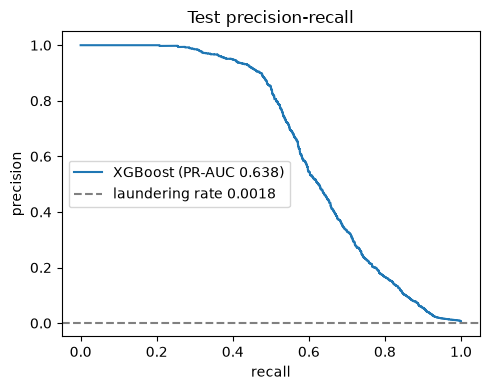

In [9]:
import matplotlib.pyplot as plt

pt, rt, _ = precision_recall_curve(y_test, p_test)
plt.figure(figsize=(5, 4))
plt.plot(rt, pt, label=f"XGBoost (PR-AUC {results.loc['xgboost @ alert', 'pr_auc']:.3f})")
plt.axhline(y_test.mean(), color="grey", ls="--", label=f"laundering rate {y_test.mean():.4f}")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("Test precision-recall"); plt.legend()
plt.tight_layout(); plt.show()

In [10]:
# which clues drive the score (gain). pass-through and new-payee clues should rank high;
# if something odd like hour is on top, check for leakage.
gain = model.get_booster().get_score(importance_type="gain")
imp = pd.Series(gain, name="gain").reindex(FEATURE_NAMES).fillna(0).sort_values(ascending=False)
imp.round(1).head(15)

fmt_ACH             92195.8
fmt_Wire            24762.4
snd_payees_24h       9392.5
snd_out_count_1h     9203.7
new_payee            8815.2
self_transfer        7964.9
cross_bank           5644.5
fmt_Credit_Card      5457.6
fmt_Cheque           4998.7
cross_currency       3655.5
fmt_Bitcoin          3543.9
fmt_Cash             3338.3
snd_out_sum_24h      3115.8
log_amount           2593.1
snd_age_days         2369.9
Name: gain, dtype: float64

In [11]:
# the three reasons: SHAP contributions for the highest-scoring test transfers
booster = model.get_booster()
top = np.argsort(-p_test)[:5]
contrib = booster.predict(xgb.DMatrix(X_test.iloc[top]), pred_contribs=True)[:, :-1]   # last column is bias
for k, i in enumerate(top):
    order = np.argsort(-contrib[k])[:3]
    reasons = [f"{FEATURE_NAMES[j]}={X_test.iloc[i, j]:.2f} (+{contrib[k, j]:.2f})" for j in order]
    print(f"txn {int(test.txn_id.iloc[i])}  score {p_test[i]:.3f}  label {int(y_test.iloc[i])}  ->  {', '.join(reasons)}")

txn 4990004  score 0.999  label 1  ->  fmt_ACH=1.00 (+3.13), mins_since_snd_last_in=0.00 (+1.09), log_amount=4.17 (+0.83)
txn 5077432  score 0.999  label 1  ->  fmt_ACH=1.00 (+3.16), new_payee=1.00 (+1.00), mins_since_snd_last_in=0.00 (+0.98)
txn 5034248  score 0.999  label 1  ->  fmt_ACH=1.00 (+3.42), mins_since_snd_last_in=0.00 (+1.10), new_payee=1.00 (+0.86)
txn 4596816  score 0.999  label 1  ->  fmt_ACH=1.00 (+3.29), mins_since_snd_last_in=0.00 (+1.06), log_amount=4.11 (+0.95)
txn 5077444  score 0.999  label 1  ->  fmt_ACH=1.00 (+3.35), mins_since_snd_last_in=0.00 (+1.17), new_payee=1.00 (+0.87)


## 6. Sanity checks

**Clue averages**: each clue should differ between laundering and normal rows in a sensible direction.
This table is a pitch slide.

**Leakage test**: push the first 1,000 transfers through a fresh `ClueBuilder` one at a time using the live `compute()` path
(text fields, exactly as they arrive from Redis) and compare with the offline table. They must match exactly.

In [12]:
means = feat.groupby("label")[FEATURE_NAMES].mean().T
means.columns = ["normal", "laundering"]
means["ratio"] = means.laundering / means.normal.replace(0, np.nan)
means.round(3)

,normal,laundering,ratio
log_amount,3.023000e+00,3.713000e+00,1.228
is_round,0.000000e+00,0.000000e+00,1.593
fmt_ACH,1.180000e-01,8.660000e-01,7.367
fmt_Bitcoin,2.900000e-02,1.100000e-02,0.376
fmt_Cash,9.700000e-02,2.100000e-02,0.216
fmt_Cheque,3.670000e-01,6.300000e-02,0.170
fmt_Credit_Card,2.610000e-01,4.000000e-02,0.153
fmt_Reinvestment,9.500000e-02,0.000000e+00,0.000
fmt_Wire,3.400000e-02,0.000000e+00,0.000
cross_currency,1.400000e-02,0.000000e+00,0.000


In [13]:
head = df.head(1000)
live = ClueBuilder()
rows = []
for r in head.itertuples(index=False):
    msg = {  # exactly the txns-stream fields, all text
        "txn_id": str(r.txn_id), "ts": pd.Timestamp(r.ts).isoformat(),
        "from_acct": str(r.from_acct), "to_acct": str(r.to_acct), "amount_usd": str(r.amount_usd),
        "amt_paid": str(r.amt_paid), "ccy_paid": str(r.ccy_paid),
        "amt_recv": str(r.amt_recv), "ccy_recv": str(r.ccy_recv), "fmt": str(r.fmt),
    }
    rows.append(live.compute(msg))
live_X = pd.DataFrame(rows)[FEATURE_NAMES].to_numpy(dtype=np.float32)
offline_X = feat[FEATURE_NAMES].head(1000).to_numpy(dtype=np.float32)
mismatch = np.abs(live_X - offline_X).max()
print("max difference live vs offline:", mismatch)
assert mismatch == 0, "live and offline clues differ: train/serve skew"
print("leakage test passed")

max difference live vs offline: 0.0
leakage test passed


## Files written

| File | Used by |
|------|---------|
| `data/features.csv` | GNN training |
| `models/scorer.json` | scorer |
| `models/feature_list.json` | scorer, rings |
| `models/thresholds.json` | scorer, rings |

Inputs `data/clean.csv` and `data/splits.json` come from Pair 1's `scripts/clean_data.py`.
Numbers for the pitch: the test table in section 5, the validation PR-AUC in section 3, and the clue averages in section 6.